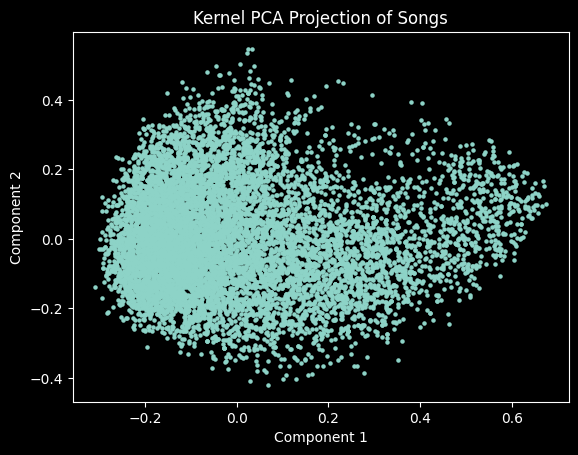

In [23]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.decomposition import KernelPCA
import matplotlib.pyplot as plt

# Load in dataset
df = pd.read_csv("spotify.csv")

# drop rows of missing key identifiers
df = df.dropna(subset = ["track_name", "artists"])

#handle missing values
df = df.fillna(df.mean(numeric_only = True))

#convert bool to numeric
df["explicit"] = df["explicit"].astype(int)

# Drop non-useful 
drop_cols = [
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre"
]

df_clean = df.drop(columns=drop_cols)

#select features
features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "explicit"
]

X = df_clean[features]

#handle outliers
X = X.clip(lower=X.quantile(0.01),
           upper=X.quantile(0.99),
           axis=1)

#Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# subset for kernal PCA
sample_size = 10000
df_sample = df.sample(sample_size, random_state=42)
df_sample = df_sample.copy()

X_sample = X_scaled[df_sample.index]

# apply kernel PCA
kpca = KernelPCA(
    n_components=2,
    kernel="rbf",
    gamma=0.01,
    random_state=42
)

X_kpca = kpca.fit_transform(X_sample)

# add back to df
df_sample["kpca_1"] = X_kpca[:, 0]
df_sample["kpca_2"] = X_kpca[:, 1]


plt.scatter(df_sample["kpca_1"], df_sample["kpca_2"], s=5)
plt.title("Kernel PCA Projection of Songs")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

Reduced from 15 features to 12 components
Variance explained: 0.940


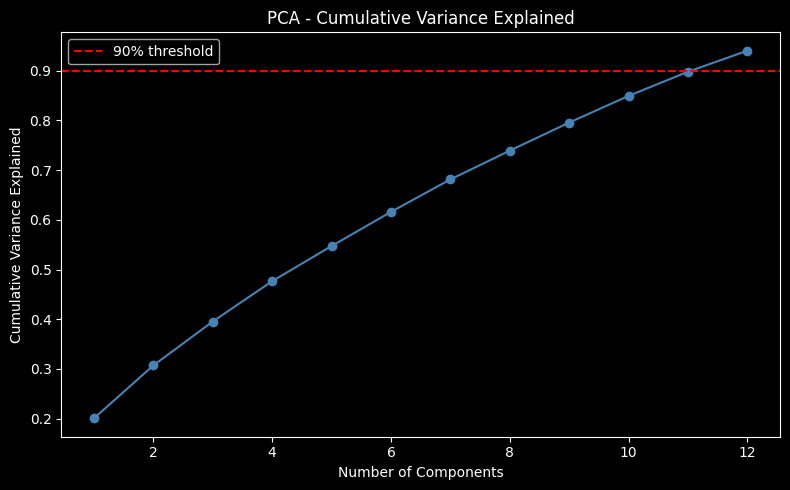

In [24]:
from sklearn.decomposition import PCA

# Run regular PCA on the full dataset (all 114,000 songs)
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Reduced from {X_scaled.shape[1]} features to {X_pca.shape[1]} components")
print(f"Variance explained: {sum(pca.explained_variance_ratio_):.3f}")

# Variance explained plot
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='steelblue')
plt.axhline(y=0.90, color='red', linestyle='--', label='90% threshold')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.title("PCA - Cumulative Variance Explained")
plt.legend()
plt.tight_layout()
plt.show()

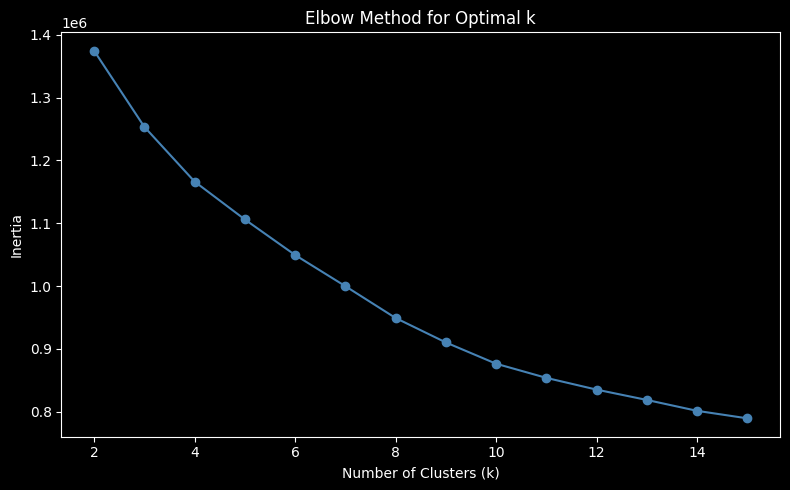

In [25]:
from sklearn.cluster import KMeans

# Elbow method to find optimal k
inertia = []
k_values = range(2, 16)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertia.append(km.inertia_)

# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o', color='steelblue')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.tight_layout()
plt.show()

K-Means done. Cluster distribution:
kmeans_cluster
0     6705
1    21034
2    18178
3     7082
4     4563
5    10580
6    30240
7     7190
8     8427
Name: count, dtype: int64


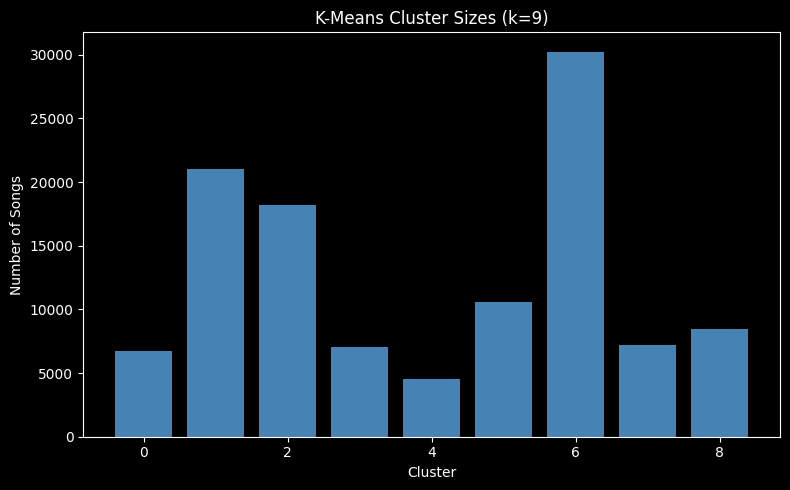

In [26]:
BEST_K = 9

kmeans = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

# Save cluster labels back to the original dataframe
df["kmeans_cluster"] = kmeans_labels

print("K-Means done. Cluster distribution:")
print(df["kmeans_cluster"].value_counts().sort_index())

# Plot bar chart of cluster sizes for K-Means
plt.figure(figsize=(8, 5))
cluster_counts = df["kmeans_cluster"].value_counts().sort_index()
plt.bar(cluster_counts.index, cluster_counts.values, color="steelblue")
plt.xlabel("Cluster")
plt.ylabel("Number of Songs")
plt.title("K-Means Cluster Sizes (k=9)")
plt.tight_layout()
plt.show()

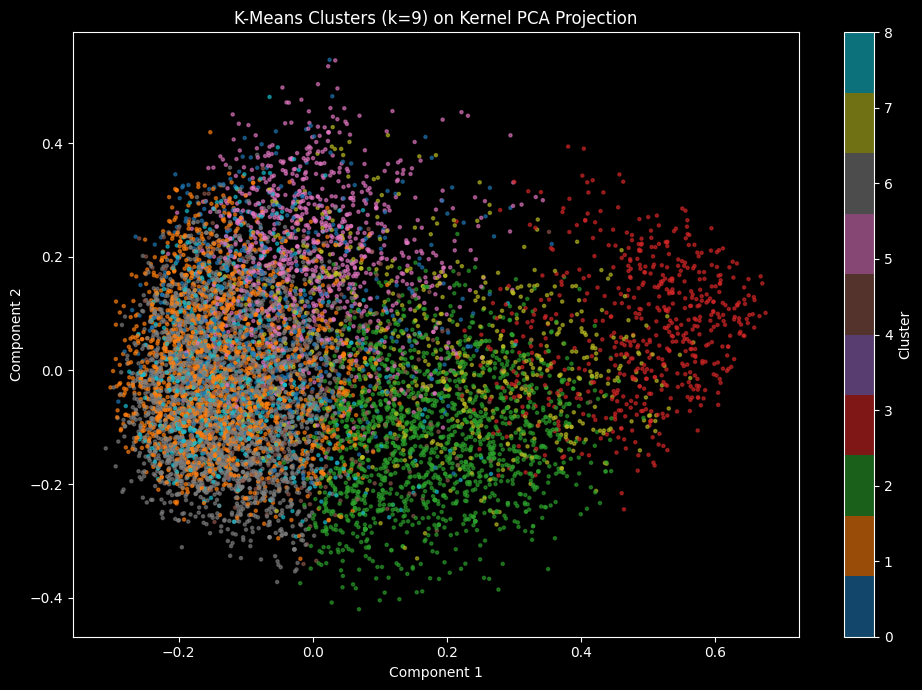

In [27]:
# Use the 10k sample and map kmeans labels back to the sample
sample_kmeans_labels = kmeans_labels[df_sample.index]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df_sample["kpca_1"],
    df_sample["kpca_2"],
    c=sample_kmeans_labels,
    cmap="tab10",
    s=5,
    alpha=0.6
)
plt.colorbar(scatter, label="Cluster")
plt.title("K-Means Clusters (k=9) on Kernel PCA Projection")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()

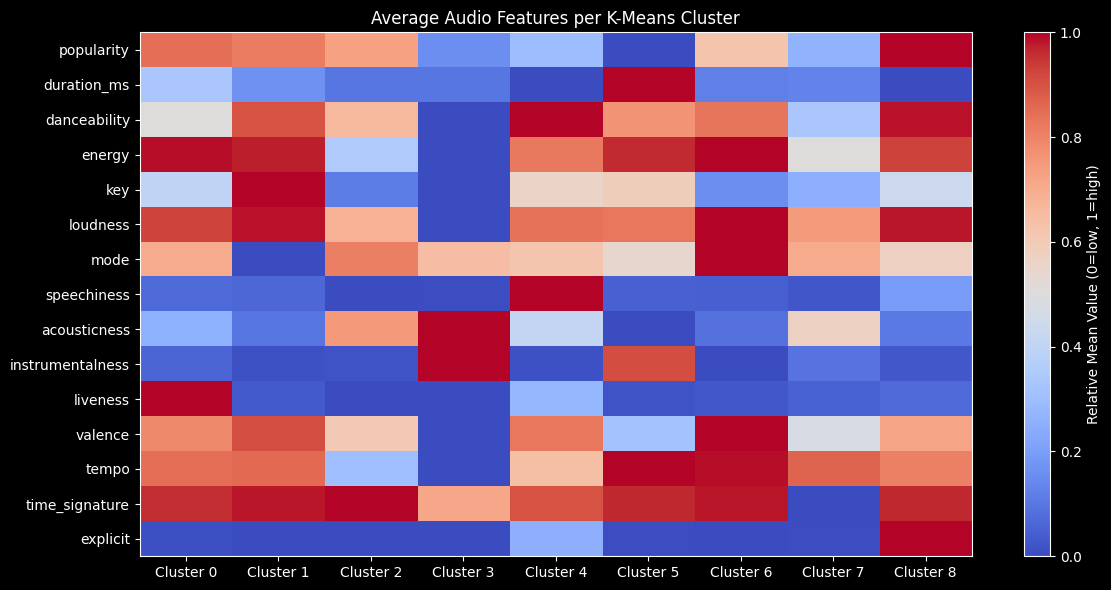

In [31]:
cluster_profiles = df.groupby("kmeans_cluster")[features].mean()

# Normalize across each feature (column), not each cluster (row)
cluster_profiles_normalized = (cluster_profiles - cluster_profiles.min()) / (cluster_profiles.max() - cluster_profiles.min())

# Heatmap of Average Audio Features per K-Means Cluster
plt.figure(figsize=(12, 6))
plt.imshow(cluster_profiles_normalized.T, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Relative Mean Value (0=low, 1=high)")
plt.xticks(range(9), [f"Cluster {i}" for i in range(9)])
plt.yticks(range(len(features)), features)
plt.title("Average Audio Features per K-Means Cluster")
plt.tight_layout()
plt.show()

## Initial DBSCAN Exploration
We first attempted DBSCAN on the 2D Kernel PCA projection as an exploratory step.
The results showed poor cluster separation, which led us to run DBSCAN on the full
PCA-reduced dataset instead (see Cell 8).

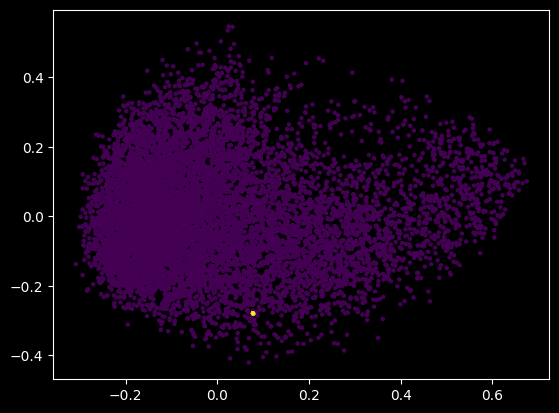

In [28]:
from sklearn.cluster import DBSCAN

coords = KernelPCA(n_components=2, kernel="rbf", gamma=0.01).fit_transform(X_sample)

labels = DBSCAN(eps=0.8, min_samples=10).fit_predict(X_sample)

plt.scatter(coords[:, 0], coords[:, 1], c=labels, s=5, cmap="viridis")
plt.show()

DBSCAN requires dense regions separated by empty space to form meaningful clusters.
Music audio features form a continuous distribution without clear density boundaries,
causing DBSCAN to merge most songs into one or two dominant clusters. This makes
K-Means the more suitable algorithm for this recommendation task.

In [30]:
# Runtime takes about 8 minutes
dbscan = DBSCAN(eps=2.0, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_pca)

df["dbscan_cluster"] = dbscan_labels

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"DBSCAN clusters found: {n_clusters}")
print(f"Noise points: {n_noise}")
print(f"\nCluster distribution:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clusters found: 25
Noise points: 2430

Cluster distribution:
-1      2430
 0     33322
 1     59180
 2      6229
 3      4929
 4      2687
 5       660
 6       273
 7      3523
 8        42
 9        12
 10       24
 11      118
 12      105
 13       63
 14      146
 15       92
 16       30
 17       25
 18       29
 19       17
 20        8
 21       10
 22       11
 23       13
 24       21
Name: count, dtype: int64


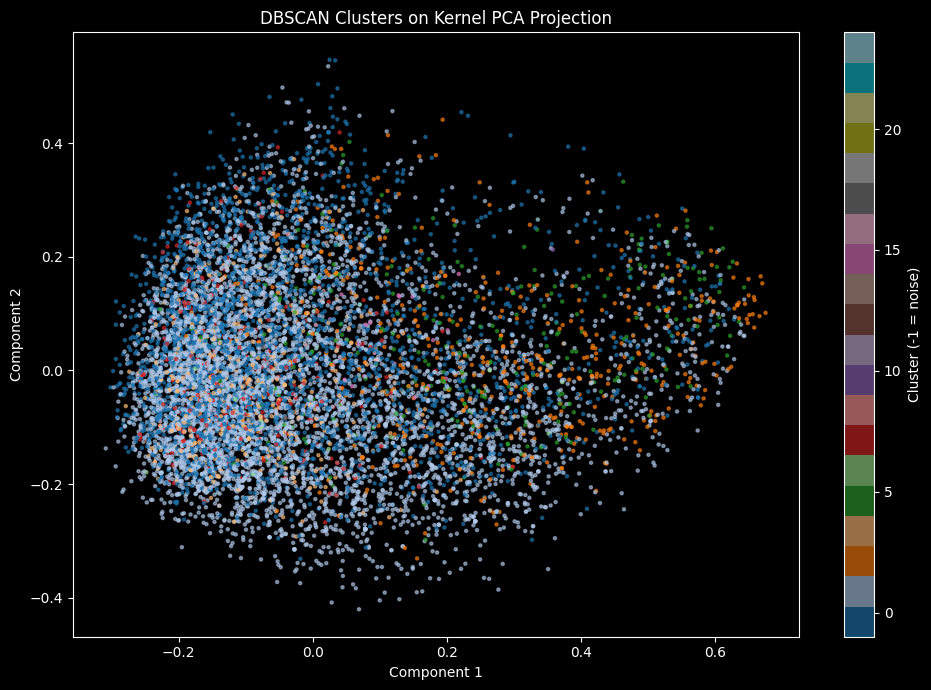

In [52]:
# Visualize DBSCAN clusters on Kernel PCA projection
sample_dbscan_labels = dbscan_labels[df_sample.index]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df_sample["kpca_1"],
    df_sample["kpca_2"],
    c=sample_dbscan_labels,
    cmap="tab20",
    s=5,
    alpha=0.6
)
plt.colorbar(scatter, label="Cluster (-1 = noise)")
plt.title("DBSCAN Clusters on Kernel PCA Projection")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics.pairwise import cosine_similarity

df = df.reset_index(drop=True)

def recommend_songs(song_name, df, X_scaled, n=5, artist=None):
    matches = df[df["track_name"].str.lower() == song_name.lower()]

    if artist:
        matches = matches[matches["artists"].str.lower().str.contains(artist.lower())]

    if matches.empty:
        print(f"Song '{song_name}' not found in dataset.")
        return

    song_idx = matches.index[0]
    song_cluster = df.loc[song_idx, "kmeans_cluster"]

    cluster_songs = df[
        (df["kmeans_cluster"] == song_cluster) &
        (df["track_name"].str.lower() != song_name.lower())
    ]
    cluster_indices = cluster_songs.index

    song_vector = X_scaled[song_idx].reshape(1, -1)
    cluster_vectors = X_scaled[cluster_indices]
    similarities = cosine_similarity(song_vector, cluster_vectors)[0]

    top_indices = similarities.argsort()[::-1][:n*3]  # grab extra to account for duplicates
    recommended = cluster_songs.iloc[top_indices].drop_duplicates(subset=["track_name", "artists"]).head(n)

    # ── Readable output ───────────────────────────────────────────────────────
    print("=" * 50)
    print(f"Input Song:  {df.loc[song_idx, 'track_name']}")
    print(f"Artist:      {df.loc[song_idx, 'artists']}")
    print(f"Genre:       {df.loc[song_idx, 'track_genre']}")
    print(f"Cluster:     {song_cluster}")
    print("=" * 50)
    print(f"Top {n} Recommendations:")
    print("-" * 50)
    for i, (_, row) in enumerate(recommended.iterrows(), 1):
        print(f"{i}. {row['track_name']}")
        print(f"   Artist:  {row['artists']}")
        print(f"   Genre:   {row['track_genre']}")
        print(f"   Popular: {row['popularity']}")
        print()

recommend_songs("Blinding Lights", df, X_scaled, artist="The Weeknd")
recommend_songs("Lose Yourself - From \"8 Mile\" Soundtrack", df, X_scaled, artist="Eminem")
recommend_songs("Sweet Child O' Mine", df, X_scaled, artist="Guns N' Roses")

Input Song:  Blinding Lights
Artist:      The Weeknd
Genre:       pop
Cluster:     6
Top 5 Recommendations:
--------------------------------------------------
1. Secrets
   Artist:  OneRepublic
   Genre:   rock
   Popular: 76

2. All The Highs
   Artist:  San Holo
   Genre:   electronic
   Popular: 58

3. Thunder
   Artist:  Imagine Dragons
   Genre:   rock
   Popular: 85

4. Tomorrow
   Artist:  Fly By Midnight
   Genre:   electro
   Popular: 64

5. Fireflies
   Artist:  Owl City
   Genre:   rock
   Popular: 79

Input Song:  Lose Yourself - From "8 Mile" Soundtrack
Artist:      Eminem
Genre:       hip-hop
Cluster:     8
Top 5 Recommendations:
--------------------------------------------------
1. Fair Trade (with Travis Scott)
   Artist:  Drake;Travis Scott
   Genre:   hip-hop
   Popular: 83

2. Till I Collapse
   Artist:  Eminem;Nate Dogg
   Genre:   hip-hop
   Popular: 86

3. Callaita
   Artist:  Bad Bunny;Tainy
   Genre:   reggaeton
   Popular: 80

4. No Limit
   Artist:  G-Eazy;A$A

In [50]:
from sklearn.metrics import silhouette_score, f1_score
from scipy.optimize import linear_sum_assignment
import numpy as np
import pandas as pd

# -------------------------------------------------
# 1. Silhouette Score (no true labels needed)
# -------------------------------------------------
sil_score = silhouette_score(X_pca, kmeans_labels)
print("Silhouette Score (K-Means):", sil_score)



Silhouette Score (K-Means): 0.13318595588148574


In [51]:
if "track_genre" in df.columns:

    true_labels = df["track_genre"].astype("category").cat.codes

    # ---- Step 1: match cluster IDs to genre labels ----
    # build confusion matrix between clusters and genres
    contingency = pd.crosstab(kmeans_labels, true_labels).values

    # Hungarian algorithm to best match clusters -> genres
    row_ind, col_ind = linear_sum_assignment(-contingency)

    # create mapping from cluster -> best genre label
    cluster_to_genre = {row: col for row, col in zip(row_ind, col_ind)}

    # remap predicted clusters
    mapped_clusters = np.array([cluster_to_genre[c] for c in kmeans_labels])

    # compute F1 score
    f1 = f1_score(true_labels, mapped_clusters, average="weighted")

    print("Weighted F1-score (cluster vs genre alignment):", f1)

else:
    print("track_genre not found: skipping F1-score calculation")

Weighted F1-score (cluster vs genre alignment): 0.0093807926754047


In [57]:
# Show sample songs from each cluster to illustrate what each cluster represents
print("Sample Songs per Cluster")
print("=" * 60)

for cluster_id in sorted(df["kmeans_cluster"].unique()):
    print(f"\nCluster {cluster_id}:")
    sample = df[df["kmeans_cluster"] == cluster_id][
        ["track_name", "artists", "track_genre", "popularity"]
    ].drop_duplicates(subset=["track_name"]).nlargest(5, "popularity")

    for _, row in sample.iterrows():
        print(f"  - {row['track_name']} by {row['artists']} ({row['track_genre']})")

print("=" * 60)

Sample Songs per Cluster

Cluster 0:
  - You Proof by Morgan Wallen (country)
  - Feel Good Inc. by Gorillaz (alternative)
  - Numb by Linkin Park (alternative)
  - Don't Stop Believin' by Journey (hard-rock)
  - death bed (coffee for your head) by Powfu;beabadoobee (sad)

Cluster 1:
  - La Bachata by Manuel Turizo (latin)
  - Tití Me Preguntó by Bad Bunny (latin)
  - Efecto by Bad Bunny (latin)
  - Ojitos Lindos by Bad Bunny;Bomba Estéreo (latin)
  - As It Was by Harry Styles (pop)

Cluster 2:
  - I Wanna Be Yours by Arctic Monkeys (garage)
  - Running Up That Hill (A Deal With God) by Kate Bush (piano)
  - Gangsta's Paradise by Coolio;L.V. (funk)
  - I Love You So by The Walters (indie)
  - lovely (with Khalid) by Billie Eilish;Khalid (pop)

Cluster 3:
  - Clean White Noise - Loopable with no fade by White Noise Baby Sleep;White Noise for Babies (sleep)
  - Lights Are On by Tom Rosenthal (british)
  - Fourth of July by Sufjan Stevens (singer-songwriter)
  - Brown Sleep Noise by Sleep